In [1]:
# Cell 1: import library
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from urllib.parse import quote_plus
from sqlalchemy import create_engine, text
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, roc_auc_score, average_precision_score

In [2]:
# Cell 2: connect to MySQL
PROJECT_ROOT = Path.cwd().parent
load_dotenv(PROJECT_ROOT / ".env")
user = os.getenv("MYSQL_USER")
pwd = quote_plus(os.getenv("MYSQL_PASSWORD"))
host = os.getenv("MYSQL_HOST")
port = os.getenv("MYSQL_PORT")
db = os.getenv("MYSQL_DB")
engine = create_engine(f"mysql+pymysql://{user}:{pwd}@{host}:{port}/{db}")
with engine.connect() as conn:
    print("Current database:", conn.execute(text("SELECT DATABASE()")).scalar())

Current database: olist_ecommerce


In [3]:
# Cell 3: geolocation columns and how many rows each zip prefix has
display(pd.read_sql(text("DESCRIBE geolocation"), engine)[["Field", "Type"]])
display(pd.read_sql(text("SELECT * FROM geolocation LIMIT 3"), engine))
with engine.connect() as conn:
    print("rows:", conn.execute(text("SELECT COUNT(*) FROM geolocation")).scalar())
    print("distinct zip prefixes:", conn.execute(text("SELECT COUNT(DISTINCT geolocation_zip_code_prefix) FROM geolocation")).scalar())

,Field,Type
0,geolocation_zip_code_prefix,int
1,geolocation_lat,double
2,geolocation_lng,double
3,geolocation_city,varchar(100)
4,geolocation_state,char(2)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP


rows: 1000163
distinct zip prefixes: 19015


In [4]:
# Cell 4: one row per delivered valid order, features known at purchase time, plus the two targets
geo = pd.read_sql(text("""
    SELECT geolocation_zip_code_prefix AS zip, AVG(geolocation_lat) AS lat, AVG(geolocation_lng) AS lng
    FROM geolocation GROUP BY geolocation_zip_code_prefix"""), engine).set_index("zip")

q = """
WITH it AS (
  SELECT i.order_id, i.order_item_id, i.seller_id, i.price, i.freight_value,
         p.product_category_name, p.product_weight_g,
         p.product_length_cm * p.product_height_cm * p.product_width_cm AS volume_cm3,
         ROW_NUMBER() OVER (PARTITION BY i.order_id ORDER BY i.price DESC, i.order_item_id) AS rn
  FROM order_items i
  JOIN valid_orders_t v ON v.order_id = i.order_id
  JOIN products p ON p.product_id = i.product_id
), agg AS (
  SELECT order_id, COUNT(*) AS n_items, COUNT(DISTINCT seller_id) AS n_sellers,
         SUM(price) AS items_price, SUM(freight_value) AS freight, SUM(product_weight_g) AS weight_g,
         MAX(CASE WHEN rn = 1 THEN seller_id END) AS main_seller,
         MAX(CASE WHEN rn = 1 THEN product_category_name END) AS main_category,
         MAX(CASE WHEN rn = 1 THEN volume_cm3 END) AS main_volume_cm3
  FROM it GROUP BY order_id
)
SELECT v.order_id, v.customer_state, c.customer_zip_code_prefix,
       v.order_purchase_timestamp, v.order_delivered_customer_date, v.order_estimated_delivery_date,
       a.n_items, a.n_sellers, a.items_price, a.freight, a.weight_g, a.main_volume_cm3, a.main_category,
       s.seller_state, s.seller_zip_code_prefix
FROM valid_orders_t v
JOIN customers c ON c.customer_id = v.customer_id
JOIN agg a ON a.order_id = v.order_id
JOIN sellers s ON s.seller_id = a.main_seller
WHERE v.order_status = 'delivered' AND v.order_delivered_customer_date IS NOT NULL
"""
data = pd.read_sql(text(q), engine, parse_dates=["order_purchase_timestamp",
                   "order_delivered_customer_date", "order_estimated_delivery_date"])
for c in ["items_price", "freight", "weight_g", "main_volume_cm3"]:
    data[c] = data[c].astype(float)

# distance between customer and seller zip-prefix centres (haversine, km)
def haversine(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

c_lat = data["customer_zip_code_prefix"].map(geo["lat"]); c_lng = data["customer_zip_code_prefix"].map(geo["lng"])
s_lat = data["seller_zip_code_prefix"].map(geo["lat"]);   s_lng = data["seller_zip_code_prefix"].map(geo["lng"])
data["distance_km"] = haversine(c_lat, c_lng, s_lat, s_lng)

# features known at purchase time, and the targets
day = pd.Timedelta(days=1)
data["est_days"] = (data["order_estimated_delivery_date"] - data["order_purchase_timestamp"]) / day
data["purchase_month"] = data["order_purchase_timestamp"].dt.month
data["purchase_weekday"] = data["order_purchase_timestamp"].dt.weekday
data["purchase_hour"] = data["order_purchase_timestamp"].dt.hour
data["total_days"] = (data["order_delivered_customer_date"] - data["order_purchase_timestamp"]) / day
data["is_late"] = data["order_delivered_customer_date"] > data["order_estimated_delivery_date"]

checks = {
    "orders = 96469":      len(data) == 96469,
    "late rate = 8.11%":   round(data["is_late"].mean() * 100, 2) == 8.11,
    "avg total days = 12.56": round(data["total_days"].mean(), 2) == 12.56,
    "avg est days = 23.74":   round(data["est_days"].mean(), 2) == 23.74,
}
for k, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", k)
print("missing distance:", int(data["distance_km"].isna().sum()),
      "| weight:", int(data["weight_g"].isna().sum()),
      "| volume:", int(data["main_volume_cm3"].isna().sum()),
      "| category:", int(data["main_category"].isna().sum()))
print(data["distance_km"].describe().round(1))
print("customer and seller in the same state:", round((data["customer_state"] == data["seller_state"]).mean() * 100, 1), "%")

PASS - orders = 96469
PASS - late rate = 8.11%
PASS - avg total days = 12.56
PASS - avg est days = 23.74
missing distance: 476 | weight: 16 | volume: 16 | category: 1358
count    95993.0
mean       600.7
std        593.6
min          0.0
25%        186.3
50%        433.9
75%        798.7
max       8677.9
Name: distance_km, dtype: float64
customer and seller in the same state: 36.0 %


C:\Users\ASUS\AppData\Local\Temp\ipykernel_21712\4276067372.py:52: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["purchase_weekday"] = data["order_purchase_timestamp"].dt.weekday


In [5]:
# Cell 4b: drop coordinates outside Brazil, average per zip prefix with the median, recompute the distance
print("distance > 4500 km before the fix:", int((data["distance_km"] > 4500).sum()), "| max:", round(data["distance_km"].max(), 1))

geo_raw = pd.read_sql(text("""SELECT geolocation_zip_code_prefix AS zip,
                                     geolocation_lat AS lat, geolocation_lng AS lng FROM geolocation"""), engine)
inside = geo_raw["lat"].between(-34, 6) & geo_raw["lng"].between(-74, -33)   # rough bounding box of Brazil
print("coordinate rows outside the Brazil box:", int((~inside).sum()), "of", len(geo_raw))
geo2 = geo_raw[inside].groupby("zip")[["lat", "lng"]].median()

c_lat = data["customer_zip_code_prefix"].map(geo2["lat"]); c_lng = data["customer_zip_code_prefix"].map(geo2["lng"])
s_lat = data["seller_zip_code_prefix"].map(geo2["lat"]);   s_lng = data["seller_zip_code_prefix"].map(geo2["lng"])
data["distance_km"] = haversine(c_lat, c_lng, s_lat, s_lng)

print("distance > 4500 km after the fix:", int((data["distance_km"] > 4500).sum()), "| max:", round(data["distance_km"].max(), 1))
print("missing distance:", int(data["distance_km"].isna().sum()))
print(data["distance_km"].describe().round(1))

distance > 4500 km before the fix: 4 | max: 8677.9
coordinate rows outside the Brazil box: 42 of 1000163
distance > 4500 km after the fix: 0 | max: 3398.5
missing distance: 477
count    95992.0
mean       600.4
std        592.4
min          0.0
25%        185.2
50%        433.8
75%        798.3
max       3398.5
Name: distance_km, dtype: float64


In [6]:
# Cell 5: feature lists, leakage check, and a split by purchase date (train < Mar 2018, valid Mar-Apr, test May-Aug 2018)
FEATURES_NUM = ["est_days", "distance_km", "n_items", "n_sellers", "items_price", "freight",
                "weight_g", "main_volume_cm3", "purchase_month", "purchase_weekday", "purchase_hour"]
FEATURES_CAT = ["customer_state", "seller_state", "main_category"]
FEATURES = FEATURES_NUM + FEATURES_CAT

forbidden = {"total_days", "is_late", "order_delivered_customer_date", "delay_days",
             "review_score", "approval_days", "handling_days", "transit_days"}
print("PASS" if not forbidden & set(FEATURES) else "FAIL", "- no feature is known only after delivery")

t = data["order_purchase_timestamp"]
data["split"] = np.where(t < "2018-03-01", "train", np.where(t < "2018-05-01", "valid", "test"))

summary = data.groupby("split").agg(
    orders=("order_id", "size"),
    first_purchase=("order_purchase_timestamp", "min"),
    last_purchase=("order_purchase_timestamp", "max"),
    late_rate_pct=("is_late", lambda s: s.mean() * 100),
    mean_total_days=("total_days", "mean"),
    mean_est_days=("est_days", "mean"),
    baseline_mae_days=("total_days", lambda s: (s - data.loc[s.index, "est_days"]).abs().mean()),
).round(2)
display(summary.loc[["train", "valid", "test"]])
print("PASS" if summary["orders"].sum() == 96469 else "FAIL", "- splits cover 96469 orders")

PASS - no feature is known only after delivery


C:\Users\ASUS\AppData\Local\Temp\ipykernel_21712\12967276.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(2)


,orders,first_purchase,last_purchase,late_rate_pct,mean_total_days,mean_est_days,baseline_mae_days
split,,,,,,,
train,57316,2016-10-03 09:44:50,2018-02-28 23:57:55,7.66,13.63,25.00,13.05
valid,13801,2018-03-01 00:00:00,2018-04-30 23:47:26,13.46,13.94,22.84,11.48
test,25352,2018-05-01 00:02:11,2018-08-29 15:00:37,6.21,9.37,21.36,12.67


PASS - splits cover 96469 orders


In [7]:
# Cell 6: baselines the model has to beat (fitted on train only)
train = data[data["split"] == "train"]; valid = data[data["split"] == "valid"]; test = data[data["split"] == "test"]

rows = []
lin = LinearRegression().fit(train[["est_days"]], train["total_days"])
const = train["total_days"].median()
for name, d in [("valid", valid), ("test", test)]:
    y = d["total_days"]
    rows.append({"split": name,
                 "platform estimate": mean_absolute_error(y, d["est_days"]),
                 "train median (constant)": mean_absolute_error(y, np.full(len(d), const)),
                 "line on est_days": mean_absolute_error(y, lin.predict(d[["est_days"]]))})
print("MAE in days (lower is better); train median =", round(const, 2), "days")
display(pd.DataFrame(rows).set_index("split").round(2))

rows = []
for name, d in [("valid", valid), ("test", test)]:
    rows.append({"split": name, "late rate (= AP of a random guess)": d["is_late"].mean(),
                 "AUROC of est_days alone": roc_auc_score(d["is_late"], -d["est_days"])})
print("\nClassification baselines")
display(pd.DataFrame(rows).set_index("split").round(3))

MAE in days (lower is better); train median = 11.37 days


,platform estimate,train median (constant),line on est_days
split,,,
valid,11.48,7.24,6.46
test,12.67,5.32,5.08



Classification baselines


,late rate (= AP of a random guess),AUROC of est_days alone
split,,
valid,0.135,0.500
test,0.062,0.715


## **delivery time regression (validation period)**

In [8]:
# Cell 7: gradient boosting for total delivery days, compared with the baselines (validation period)
for c in FEATURES_CAT:
    data[c] = data[c].astype("category")
train = data[data["split"] == "train"]; valid = data[data["split"] == "valid"]
Xtr, Xva = train[FEATURES], valid[FEATURES]
ytr, yva = train["total_days"], valid["total_days"]

lin = LinearRegression().fit(train[["est_days"]], ytr)
print("baseline MAE on valid: platform", round(mean_absolute_error(yva, valid["est_days"]), 2),
      "| line on est_days", round(mean_absolute_error(yva, lin.predict(valid[["est_days"]])), 2))

rows = []
for lr in [0.05, 0.1]:
    for leaves in [15, 31]:
        m = HistGradientBoostingRegressor(loss="absolute_error", learning_rate=lr, max_leaf_nodes=leaves,
                                          max_iter=300, min_samples_leaf=50,
                                          categorical_features="from_dtype", random_state=42).fit(Xtr, ytr)
        p = m.predict(Xva)
        rows.append({"learning_rate": lr, "max_leaf_nodes": leaves,
                     "valid_MAE": mean_absolute_error(yva, p),
                     "valid_median_abs_error": np.median(np.abs(yva - p)),
                     "mean_error (bias)": (p - yva).mean()})
res = pd.DataFrame(rows).round(2)
display(res)

baseline MAE on valid: platform 11.48 | line on est_days 6.46


,learning_rate,max_leaf_nodes,valid_MAE,valid_median_abs_error,mean_error (bias)
0,0.05,15,5.79,3.40,-2.97
1,0.05,31,5.83,3.47,-2.91
2,0.10,15,5.78,3.39,-3.03
3,0.10,31,5.81,3.41,-2.98


## **late vs not late classifier (validation period)**

In [9]:
# Cell 8: gradient boosting for "late or not" (validation period)
ytr_c, yva_c = train["is_late"].astype(int), valid["is_late"].astype(int)
print("valid late rate (AP of a random guess):", round(yva_c.mean(), 3),
      "| AUROC of est_days alone: 0.500 (from Cell 6)")

rows = []
for lr in [0.05, 0.1]:
    for leaves in [15, 31]:
        m = HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, max_iter=300,
                                           min_samples_leaf=50, categorical_features="from_dtype",
                                           random_state=42).fit(Xtr, ytr_c)
        p = m.predict_proba(Xva)[:, 1]
        rows.append({"learning_rate": lr, "max_leaf_nodes": leaves,
                     "valid_AUROC": roc_auc_score(yva_c, p),
                     "valid_AP": average_precision_score(yva_c, p)})
display(pd.DataFrame(rows).round(3))

valid late rate (AP of a random guess): 0.135 | AUROC of est_days alone: 0.500 (from Cell 6)


,learning_rate,max_leaf_nodes,valid_AUROC,valid_AP
0,0.05,15,0.710,0.272
1,0.05,31,0.676,0.246
2,0.10,15,0.696,0.253
3,0.10,31,0.678,0.240


In [10]:
# Cell 9: FINAL test-period evaluation. Fit on train+valid, settings fixed from the validation results
dev = data[data["split"].isin(["train", "valid"])]
test = data[data["split"] == "test"].copy()
Xdev, Xte = dev[FEATURES], test[FEATURES]
yte = test["total_days"]

# --- regression ---
reg = HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.1, max_leaf_nodes=15,
                                    max_iter=300, min_samples_leaf=50,
                                    categorical_features="from_dtype", random_state=42).fit(Xdev, dev["total_days"])
p_reg = reg.predict(Xte)
lin = LinearRegression().fit(dev[["est_days"]], dev["total_days"])
const = dev["total_days"].median()
preds = {"platform estimate": test["est_days"].to_numpy(),
         "train+valid median": np.full(len(test), const),
         "line on est_days": lin.predict(test[["est_days"]]),
         "gradient boosting": p_reg}
reg_res = pd.DataFrame({k: {"MAE": mean_absolute_error(yte, v),
                            "median abs error": np.median(np.abs(yte - v)),
                            "mean error (bias)": (v - yte).mean()} for k, v in preds.items()}).T.round(2)
print("Regression on the test period (days)")
display(reg_res)

test["abs_err_model"] = np.abs(yte - p_reg)
test["abs_err_line"] = np.abs(yte - preds["line on est_days"])
print("MAE by purchase month (test period)")
display(test.groupby("purchase_month")[["abs_err_model", "abs_err_line"]].mean().round(2))

# --- classification ---
clf = HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=15, max_iter=300,
                                     min_samples_leaf=50, categorical_features="from_dtype",
                                     random_state=42).fit(Xdev, dev["is_late"].astype(int))
p_clf = clf.predict_proba(Xte)[:, 1]
y_c = test["is_late"].astype(int).to_numpy()
print("\nClassification on the test period")
print("late rate (AP of a random guess):", round(y_c.mean(), 3))
print("AUROC: model", round(roc_auc_score(y_c, p_clf), 3), "| est_days alone", round(roc_auc_score(y_c, -test['est_days']), 3))
print("AP:    model", round(average_precision_score(y_c, p_clf), 3))

thr = np.quantile(p_clf, 0.90)
flag = p_clf >= thr
print(f"flagging the 10% riskiest orders: precision {y_c[flag].mean() * 100:.1f}%, "
      f"recall {y_c[flag].sum() / y_c.sum() * 100:.1f}% of all late orders")

Regression on the test period (days)


,MAE,median abs error,mean error (bias)
platform estimate,12.67,11.33,11.98
train+valid median,5.29,4.75,1.94
line on est_days,5.21,4.28,2.82
gradient boosting,3.72,2.71,0.36


MAE by purchase month (test period)


,abs_err_model,abs_err_line
purchase_month,,
5,4.38,5.74
6,3.87,7.12
7,3.60,4.59
8,2.98,3.40



Classification on the test period
late rate (AP of a random guess): 0.062
AUROC: model 0.728 | est_days alone 0.715
AP:    model 0.132
flagging the 10% riskiest orders: precision 14.7%, recall 23.7% of all late orders


In [11]:
# Cell 10: permutation importance on the test period (descriptive; nothing is tuned from this)
from sklearn.inspection import permutation_importance

imp_r = permutation_importance(reg, Xte, yte, scoring="neg_mean_absolute_error",
                               n_repeats=5, random_state=42, n_jobs=-1)
imp_c = permutation_importance(clf, Xte, y_c, scoring="roc_auc",
                               n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.DataFrame({"MAE increase (days) if shuffled": imp_r.importances_mean,
                    "AUROC drop if shuffled": imp_c.importances_mean}, index=FEATURES)
display(imp.sort_values("MAE increase (days) if shuffled", ascending=False).round(3))

,MAE increase (days) if shuffled,AUROC drop if shuffled
distance_km,0.274,0.002
est_days,0.266,0.223
customer_state,0.134,0.028
main_category,0.063,0.007
seller_state,0.039,0.005
purchase_weekday,0.036,0.001
main_volume_cm3,0.031,0.001
weight_g,0.018,-0.000
n_items,0.015,0.001
items_price,0.012,-0.000


## **rolling-origin yardstick with the current features**

In [12]:
# Cell 11: rolling-origin validation (3 folds inside train+valid) for the CURRENT features; the test period is not used here
folds = [("2017-11-01", "2018-01-01"), ("2018-01-01", "2018-03-01"), ("2018-03-01", "2018-05-01")]
dev = data[data["split"].isin(["train", "valid"])]
ts = dev["order_purchase_timestamp"]

def evaluate_fold(features, tr, va):
    y = va["is_late"].astype(int)
    clf = HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=15, max_iter=300,
                                         min_samples_leaf=50, categorical_features="from_dtype",
                                         random_state=42).fit(tr[features], tr["is_late"].astype(int))
    p = clf.predict_proba(va[features])[:, 1]
    reg = HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.1, max_leaf_nodes=15,
                                        max_iter=300, min_samples_leaf=50, categorical_features="from_dtype",
                                        random_state=42).fit(tr[features], tr["total_days"])
    line = LinearRegression().fit(tr[["est_days"]], tr["total_days"])
    return {"train_orders": len(tr), "valid_orders": len(va), "late_rate": y.mean(),
            "AUROC_model": roc_auc_score(y, p), "AUROC_est_days": roc_auc_score(y, -va["est_days"]),
            "AP_model": average_precision_score(y, p),
            "MAE_model": mean_absolute_error(va["total_days"], reg.predict(va[features])),
            "MAE_line": mean_absolute_error(va["total_days"], line.predict(va[["est_days"]]))}

rows = []
for start, end in folds:
    tr, va = dev[ts < start], dev[(ts >= start) & (ts < end)]
    rows.append({"valid_period": f"{start} to {end}", **evaluate_fold(FEATURES, tr, va)})
cv = pd.DataFrame(rows).set_index("valid_period")
display(cv.round(3))
print("mean over folds:")
display(cv[["AUROC_model", "AUROC_est_days", "AP_model", "MAE_model", "MAE_line"]].mean().round(3))

,train_orders,valid_orders,late_rate,AUROC_model,AUROC_est_days,AP_model,MAE_model,MAE_line
valid_period,,,,,,,,
2017-11-01 to 2018-01-01,30891,12801,0.118,0.640,0.495,0.184,6.207,6.456
2018-01-01 to 2018-03-01,43692,13624,0.111,0.652,0.520,0.187,6.705,6.548
2018-03-01 to 2018-05-01,57316,13801,0.135,0.710,0.500,0.272,5.779,6.462


mean over folds:


AUROC_model       0.668
AUROC_est_days    0.505
AP_model          0.214
MAE_model         6.230
MAE_line          6.488
dtype: float64

In [13]:
# Cell 12: seller / route history and recent load, using only orders already delivered before each purchase
q = """
SELECT order_id, seller_id AS main_seller FROM (
  SELECT i.order_id, i.seller_id,
         ROW_NUMBER() OVER (PARTITION BY i.order_id ORDER BY i.price DESC, i.order_item_id) AS rn
  FROM order_items i JOIN valid_orders_t v ON v.order_id = i.order_id) x
WHERE rn = 1
"""
ms = pd.read_sql(text(q), engine)
data = data.drop(columns=[c for c in ["main_seller"] if c in data.columns]).merge(ms, on="order_id", how="left")
data = data.reset_index(drop=True)
print("PASS" if len(data) == 96469 and data["main_seller"].notna().all() else "FAIL", "- seller id attached to all 96469 orders")

t0 = data["order_purchase_timestamp"].min()
day = pd.Timedelta(days=1)
buy = ((data["order_purchase_timestamp"] - t0) / day).to_numpy()
got = ((data["order_delivered_customer_date"] - t0) / day).to_numpy()
late = data["is_late"].astype(float).to_numpy()
days_ = data["total_days"].to_numpy()

def cum_stats(pos):
    # for each order in pos: count, late count and delivery-day sum of orders in pos delivered BEFORE its purchase
    o = np.argsort(got[pos]); g = got[pos][o]
    cl = np.concatenate([[0.0], np.cumsum(late[pos][o])])
    cd = np.concatenate([[0.0], np.cumsum(days_[pos][o])])
    j = np.searchsorted(g, buy[pos], side="left")
    return j, cl[j], cd[j]

all_pos = np.arange(len(data))
n_all, l_all, d_all = cum_stats(all_pos)
with np.errstate(invalid="ignore", divide="ignore"):
    prior_late = np.where(n_all > 0, l_all / n_all, np.nan)
    prior_days = np.where(n_all > 0, d_all / n_all, np.nan)

def history(keys, name, k=20):
    n = np.zeros(len(data)); l = np.zeros(len(data)); d = np.zeros(len(data))
    for _, pos in data.groupby(keys, observed=True).indices.items():
        n[pos], l[pos], d[pos] = cum_stats(pos)
    data[f"{name}_n_prior"] = n
    data[f"{name}_late_rate"] = (l + k * prior_late) / (n + k)
    data[f"{name}_mean_days"] = (d + k * prior_days) / (n + k)

history("main_seller", "seller")
history(["seller_state", "customer_state"], "route")

def load_7d(pos):
    b = np.sort(buy[pos]); own = buy[pos]
    return np.searchsorted(b, own, side="left") - np.searchsorted(b, own - 7, side="left")
data["platform_load_7d"] = load_7d(all_pos)
sl = np.zeros(len(data))
for _, pos in data.groupby("main_seller").indices.items():
    sl[pos] = load_7d(pos)
data["seller_load_7d"] = sl

FEATURES_HIST = ["seller_n_prior", "seller_late_rate", "seller_mean_days",
                 "route_n_prior", "route_late_rate", "route_mean_days",
                 "platform_load_7d", "seller_load_7d"]
forbidden = {"total_days", "is_late", "order_delivered_customer_date", "delay_days", "review_score"}
print("PASS" if not forbidden & set(FEATURES + FEATURES_HIST) else "FAIL", "- no feature is known only after delivery")

# leakage check: recompute the seller late rate by brute force for 5 random orders
rng = np.random.default_rng(42)
ok_all = True
for i in rng.choice(len(data), 5, replace=False):
    r = data.iloc[i]
    prev = data[(data["main_seller"] == r["main_seller"]) &
                (data["order_delivered_customer_date"] < r["order_purchase_timestamp"])]
    expected = (prev["is_late"].sum() + 20 * prior_late[i]) / (len(prev) + 20)
    ok = np.isclose(expected, r["seller_late_rate"], equal_nan=True)
    ok_all &= bool(ok)
    print(f"order {i}: earlier delivered orders of this seller = {len(prev)}, brute force {expected:.4f}, feature {r['seller_late_rate']:.4f}")
print("PASS" if ok_all else "FAIL", "- history features match the brute-force recomputation")
print(data[FEATURES_HIST].describe().round(3).T[["count", "mean", "min", "max"]])

PASS - seller id attached to all 96469 orders
PASS - no feature is known only after delivery
order 74660: earlier delivered orders of this seller = 48, brute force 0.0404, feature 0.0404
order 42337: earlier delivered orders of this seller = 295, brute force 0.0278, feature 0.0278
order 63144: earlier delivered orders of this seller = 6, brute force 0.0311, feature 0.0311
order 8609: earlier delivered orders of this seller = 37, brute force 0.0649, feature 0.0649
order 41772: earlier delivered orders of this seller = 11, brute force 0.0333, feature 0.0333
PASS - history features match the brute-force recomputation
                    count      mean    min        max
seller_n_prior    96469.0   168.686  0.000   1780.000
seller_late_rate  96204.0     0.055  0.000      0.359
seller_mean_days  96204.0    12.392  6.826     27.319
route_n_prior     96469.0  5676.349  0.000  30427.000
route_late_rate   96204.0     0.054  0.000      0.284
route_mean_days   96204.0    12.214  6.703     25.753


In [14]:
# Cell 13: same folds as Cell 11, with and without the history features (test period not used)
dev = data[data["split"].isin(["train", "valid"])]
ts = dev["order_purchase_timestamp"]
rows = []
for start, end in folds:
    tr, va = dev[ts < start], dev[(ts >= start) & (ts < end)]
    r = evaluate_fold(FEATURES + FEATURES_HIST, tr, va)
    rows.append({"valid_period": f"{start} to {end}", **r})
cv_h = pd.DataFrame(rows).set_index("valid_period")

cmp = pd.DataFrame({
    "AUROC current": cv["AUROC_model"], "AUROC + history": cv_h["AUROC_model"],
    "AP current": cv["AP_model"], "AP + history": cv_h["AP_model"],
    "MAE current": cv["MAE_model"], "MAE + history": cv_h["MAE_model"],
})
display(cmp.round(3))
print("means:")
display(cmp.mean().round(3))
print("folds where AUROC improved:", int((cv_h["AUROC_model"] > cv["AUROC_model"]).sum()), "of 3")
print("folds where MAE improved:  ", int((cv_h["MAE_model"] < cv["MAE_model"]).sum()), "of 3")

,AUROC current,AUROC + history,AP current,AP + history,MAE current,MAE + history
valid_period,,,,,,
2017-11-01 to 2018-01-01,0.640,0.640,0.184,0.198,6.207,6.194
2018-01-01 to 2018-03-01,0.652,0.734,0.187,0.272,6.705,5.945
2018-03-01 to 2018-05-01,0.710,0.709,0.272,0.292,5.779,6.168


means:


AUROC current      0.668
AUROC + history    0.694
AP current         0.214
AP + history       0.254
MAE current        6.230
MAE + history      6.102
dtype: float64

folds where AUROC improved: 1 of 3
folds where MAE improved:   2 of 3


In [15]:
# Cell A: shipping-deadline features (known at purchase), same rolling folds
sl = pd.read_sql(text("""SELECT i.order_id, MIN(i.shipping_limit_date) AS ship_limit
                         FROM order_items i JOIN valid_orders_t v ON v.order_id = i.order_id
                         GROUP BY i.order_id"""), engine, parse_dates=["ship_limit"])
data = data.drop(columns=["ship_limit"], errors="ignore").merge(sl, on="order_id", how="left")
data["ship_limit_days"] = (data["ship_limit"] - data["order_purchase_timestamp"]) / pd.Timedelta(days=1)
data["est_minus_limit"] = data["est_days"] - data["ship_limit_days"]
data["same_state"] = (data["customer_state"].astype(str) == data["seller_state"].astype(str)).astype(int)
NEW = ["ship_limit_days", "est_minus_limit", "same_state"]

dev = data[data["split"].isin(["train", "valid"])]
ts = dev["order_purchase_timestamp"]
rows = []
for start, end in folds:
    tr, va = dev[ts < start], dev[(ts >= start) & (ts < end)]
    rows.append({"valid_period": f"{start} to {end}", **evaluate_fold(FEATURES + NEW, tr, va)})
cv_n = pd.DataFrame(rows).set_index("valid_period")
cmp = pd.DataFrame({"AUROC current": cv["AUROC_model"], "AUROC + new": cv_n["AUROC_model"],
                    "AP current": cv["AP_model"], "AP + new": cv_n["AP_model"],
                    "MAE current": cv["MAE_model"], "MAE + new": cv_n["MAE_model"]})
display(cmp.round(3)); display(cmp.mean().round(3))
print("AUROC better in", int((cv_n["AUROC_model"] > cv["AUROC_model"]).sum()), "of 3 folds")
print("MAE better in  ", int((cv_n["MAE_model"] < cv["MAE_model"]).sum()), "of 3 folds")

,AUROC current,AUROC + new,AP current,AP + new,MAE current,MAE + new
valid_period,,,,,,
2017-11-01 to 2018-01-01,0.640,0.643,0.184,0.186,6.207,6.248
2018-01-01 to 2018-03-01,0.652,0.646,0.187,0.187,6.705,6.536
2018-03-01 to 2018-05-01,0.710,0.708,0.272,0.264,5.779,5.759


AUROC current    0.668
AUROC + new      0.666
AP current       0.214
AP + new         0.212
MAE current      6.230
MAE + new        6.181
dtype: float64

AUROC better in 1 of 3 folds
MAE better in   2 of 3 folds


In [16]:
# Cell 15: delivery date range from quantile regression (test period, evaluated once)
dev = data[data["split"].isin(["train", "valid"])]
test = data[data["split"] == "test"]
res = {}
for qn in [0.5, 0.9]:
    m = HistGradientBoostingRegressor(loss="quantile", quantile=qn, learning_rate=0.1, max_leaf_nodes=15,
                                      max_iter=300, min_samples_leaf=50, categorical_features="from_dtype",
                                      random_state=42).fit(dev[FEATURES], dev["total_days"])
    res[qn] = m.predict(test[FEATURES])
y = test["total_days"].to_numpy()
out = pd.DataFrame({
    "share delivered within promise": [(y <= test["est_days"]).mean(), (y <= res[0.9]).mean()],
    "average promised days": [test["est_days"].mean(), res[0.9].mean()],
}, index=["platform estimate", "model P90"]).round(3)
display(out)
print("P50 coverage:", round((y <= res[0.5]).mean(), 3), "(should be near 0.50)")

,share delivered within promise,average promised days
platform estimate,0.938,21.358
model P90,0.922,16.990


P50 coverage: 0.64 (should be near 0.50)


In [17]:
# Cell 16: is P90 coverage stable? Same three rolling folds, test period not used
dev = data[data["split"].isin(["train", "valid"])]
ts = dev["order_purchase_timestamp"]
rows = []
for start, end in folds:
    tr, va = dev[ts < start], dev[(ts >= start) & (ts < end)]
    m = HistGradientBoostingRegressor(loss="quantile", quantile=0.9, learning_rate=0.1, max_leaf_nodes=15,
                                      max_iter=300, min_samples_leaf=50, categorical_features="from_dtype",
                                      random_state=42).fit(tr[FEATURES], tr["total_days"])
    p = m.predict(va[FEATURES]); y = va["total_days"].to_numpy()
    rows.append({"valid_period": f"{start} to {end}",
                 "platform coverage": (y <= va["est_days"]).mean(),
                 "model P90 coverage": (y <= p).mean(),
                 "platform promise (days)": va["est_days"].mean(),
                 "model P90 promise (days)": p.mean()})
display(pd.DataFrame(rows).set_index("valid_period").round(3))

,platform coverage,model P90 coverage,platform promise (days),model P90 promise (days)
valid_period,,,,
2017-11-01 to 2018-01-01,0.882,0.743,24.766,18.108
2018-01-01 to 2018-03-01,0.889,0.746,25.449,18.305
2018-03-01 to 2018-05-01,0.865,0.831,22.844,19.795


In [18]:
# Cell 17 (optional): P90 shifted by an offset measured on the month before each period
dev = data[data["split"].isin(["train", "valid"])]
ts = dev["order_purchase_timestamp"]
rows = []
for start, end in folds:
    s = pd.Timestamp(start); cal_start = s - pd.DateOffset(months=1)
    tr  = dev[ts < cal_start]
    cal = dev[(ts >= cal_start) & (ts < s)]
    va  = dev[(ts >= s) & (ts < end)]
    m = HistGradientBoostingRegressor(loss="quantile", quantile=0.9, learning_rate=0.1, max_leaf_nodes=15,
                                      max_iter=300, min_samples_leaf=50, categorical_features="from_dtype",
                                      random_state=42).fit(tr[FEATURES], tr["total_days"])
    offset = np.quantile(cal["total_days"].to_numpy() - m.predict(cal[FEATURES]), 0.9)
    p = m.predict(va[FEATURES]) + offset
    y = va["total_days"].to_numpy()
    rows.append({"valid_period": f"{start} to {end}", "offset (days)": offset,
                 "platform coverage": (y <= va["est_days"]).mean(),
                 "calibrated P90 coverage": (y <= p).mean(),
                 "platform promise (days)": va["est_days"].mean(),
                 "calibrated promise (days)": p.mean()})
display(pd.DataFrame(rows).set_index("valid_period").round(3))

,offset (days),platform coverage,calibrated P90 coverage,platform promise (days),calibrated promise (days)
valid_period,,,,,
2017-11-01 to 2018-01-01,-0.477,0.882,0.764,24.766,18.926
2018-01-01 to 2018-03-01,-0.293,0.889,0.735,25.449,18.043
2018-03-01 to 2018-05-01,9.354,0.865,0.932,22.844,28.353


## **logistic regression baseline and confusion matrix**

In [19]:
# Cell 18: logistic baseline, and precision/recall/F1 for the final classifier (test period)
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import confusion_matrix

dev = data[data["split"].isin(["train", "valid"])]
test = data[data["split"] == "test"]
y_dev = dev["is_late"].astype(int).to_numpy(); y_te = test["is_late"].astype(int).to_numpy()

def cat_str(df):
    out = df[FEATURES].copy()
    for c in FEATURES_CAT:
        out[c] = out[c].astype(object).where(out[c].notna(), "unknown").astype(str)
    return out

pre = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), FEATURES_NUM),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), FEATURES_CAT)])
logit = make_pipeline(pre, LogisticRegression(max_iter=1000, class_weight="balanced")).fit(cat_str(dev), y_dev)
p_log = logit.predict_proba(cat_str(test))[:, 1]
p_gb = clf.predict_proba(test[FEATURES])[:, 1]          # final gradient boosting classifier from Cell 9

print("Test period: late rate", round(y_te.mean(), 3))
display(pd.DataFrame({"AUROC": [roc_auc_score(y_te, -test["est_days"]), roc_auc_score(y_te, p_log), roc_auc_score(y_te, p_gb)],
                      "AP": [average_precision_score(y_te, -test["est_days"]), average_precision_score(y_te, p_log), average_precision_score(y_te, p_gb)]},
                     index=["est_days alone", "logistic regression", "gradient boosting"]).round(3))

rows = []
for share in [0.10, 0.30]:
    flag = p_gb >= np.quantile(p_gb, 1 - share)
    tn, fp, fn, tp = confusion_matrix(y_te, flag).ravel()
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    rows.append({"orders flagged": f"top {share:.0%}", "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "precision": prec, "recall": rec, "F1": 2 * prec * rec / (prec + rec)})
display(pd.DataFrame(rows).round(3))

Test period: late rate 0.062


,AUROC,AP
est_days alone,0.715,0.200
logistic regression,0.705,0.126
gradient boosting,0.728,0.132


,orders flagged,TP,FP,FN,TN,precision,recall,F1
0,top 10%,373,2164,1202,21613,0.147,0.237,0.181
1,top 30%,968,6638,607,17139,0.127,0.615,0.211


## **SHAP for the final regression model**

c:\Users\ASUS\anaconda3\envs\ecommerce\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PASS - SHAP wrapper reproduces the model


PermutationExplainer explainer: 301it [00:43,  6.30it/s]                         


,mean |SHAP| (days)
distance_km,1.552
purchase_month,1.415
customer_state,1.311
est_days,1.276
freight,0.586
main_category,0.448
purchase_weekday,0.301
seller_state,0.262
n_items,0.198
main_volume_cm3,0.110


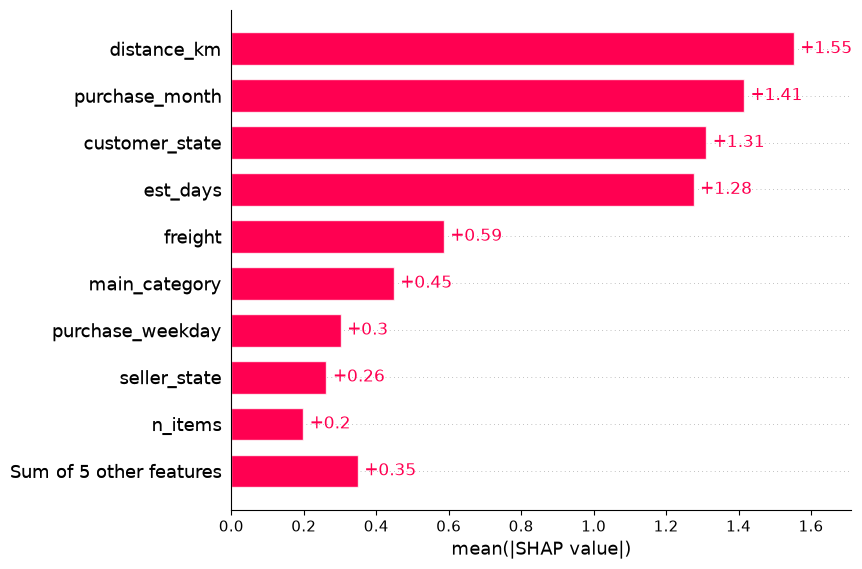

In [20]:
# Cell 19: SHAP for the final delivery-time regressor (permutation explainer, 300 test orders)
import shap
cats = {c: data[c].cat.categories for c in FEATURES_CAT}

def encode(df):
    out = df[FEATURES].copy()
    for c in FEATURES_CAT: out[c] = out[c].cat.codes.astype(float).replace(-1, np.nan)
    for c in FEATURES_NUM: out[c] = out[c].astype(float)
    return out.to_numpy()

def predict_fn(a):
    df = pd.DataFrame(a, columns=FEATURES)
    for c in FEATURES_NUM: df[c] = df[c].astype(float)
    for c in FEATURES_CAT:
        df[c] = pd.Categorical([cats[c][int(v)] if not np.isnan(v) else np.nan for v in df[c].to_numpy()], categories=cats[c])
    return reg.predict(df)                               # final regressor from Cell 9

check = test.sample(50, random_state=3)
print("PASS" if np.allclose(predict_fn(encode(check)), reg.predict(check[FEATURES])) else "FAIL", "- SHAP wrapper reproduces the model")

bg = encode(dev.sample(100, random_state=0)); smp = encode(test.sample(300, random_state=1))
explainer = shap.Explainer(predict_fn, bg, algorithm="permutation")
sv = explainer(smp, max_evals=2 * len(FEATURES) + 1)
sv.feature_names = FEATURES
display(pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES).sort_values(ascending=False).round(3).to_frame("mean |SHAP| (days)"))
shap.plots.bar(sv)

In [ ]:
# Cell 20: same folds, with and without purchase_month
no_month = [f for f in FEATURES if f != "purchase_month"]
dev = data[data["split"].isin(["train", "valid"])]; ts = dev["order_purchase_timestamp"]
rows = []
for start, end in folds:
    tr, va = dev[ts < start], dev[(ts >= start) & (ts < end)]
    rows.append({"valid_period": f"{start} to {end}", **evaluate_fold(no_month, tr, va)})
cv_m = pd.DataFrame(rows).set_index("valid_period")
print(pd.DataFrame({"MAE current": cv["MAE_model"], "MAE no month": cv_m["MAE_model"],
                    "AUROC current": cv["AUROC_model"], "AUROC no month": cv_m["AUROC_model"]}).round(3))
print("MAE better without month in", int((cv_m["MAE_model"] < cv["MAE_model"]).sum()), "of 3 folds")

                          MAE current  MAE no month  AUROC current  \
valid_period                                                         
2017-11-01 to 2018-01-01        6.207         6.305          0.640   
2018-01-01 to 2018-03-01        6.705         6.233          0.652   
2018-03-01 to 2018-05-01        5.779         5.580          0.710   

                          AUROC no month  
valid_period                              
2017-11-01 to 2018-01-01           0.626  
2018-01-01 to 2018-03-01           0.692  
2018-03-01 to 2018-05-01           0.722  
MAE better without month in 2 of 3 folds


In [22]:
# Cell 21: save the final models
import joblib
MODELS_DIR = PROJECT_ROOT / "models"; MODELS_DIR.mkdir(exist_ok=True)
joblib.dump({"model": reg, "features": FEATURES, "categories": cats, "trained_on": "orders up to 2018-04-30"},
            MODELS_DIR / "delivery_time_regressor.joblib")
print("saved:", [p.name for p in MODELS_DIR.iterdir()])

saved: ['.gitkeep', 'delivery_time_regressor.joblib']


## Delivery prediction: findings

**Task:** predict, at purchase time, (a) the delivery time in days and (b) whether an order will be delivered after the estimated date. **Data:** 96,469 delivered valid orders (reconciles with notebooks 6 and 10: late rate 8.11%, average delivery 12.56 days, average estimate 23.74 days).

### Setup
- **Features known at purchase:** estimated delivery days, customer-seller distance (km), customer and seller state, main category, number of items and sellers, price, freight, weight, volume, purchase month, weekday and hour. Nothing recorded after purchase is used (checked in code).
- **Distance:** computed from the median zip-prefix coordinates. 42 coordinate rows outside Brazil were dropped (the maximum distance fell from 8,678 km to 3,399 km). 477 orders have no distance and are kept as missing values.
- **Time-based split:** train up to 2018-02-28 (57,316 orders), validation March to April 2018 (13,801), test May to August 2018 (25,352). Settings were fixed on the validation period. The test period was then used to report the final models (point estimate, classifier, date range, baselines, importance); nothing was tuned from it.
- **Model:** gradient boosting. Regression uses the absolute-error loss.
- **Baselines:** the platform's own estimate, a constant (median), a straight line on the estimated days, and (for late or not) logistic regression and the estimated days alone.

### Delivery time (regression, test period)
| Model | MAE (days) | Median abs. error | Bias (days) |
|---|---|---|---|
| Platform estimate | 12.67 | 11.33 | +11.98 |
| Median of train+valid | 5.29 | 4.75 | +1.94 |
| Line on estimated days | 5.21 | 4.28 | +2.82 |
| **Gradient boosting** | **3.72** | **2.71** | +0.36 |

- The platform estimate is about 12 days longer than actual delivery, so it is a weak baseline. Against the line, the model reduces the error by 29% (5.21 to 3.72).
- The model beats the line in every test month: May 4.38 vs 5.74, June 3.87 vs 7.12, July 3.60 vs 4.59, August 2.98 vs 3.40.
- **Caution:** across three earlier validation periods (Nov 2017 to Apr 2018) the model was only 4% better than the line on average (MAE 6.23 vs 6.49), and worse in Jan to Feb 2018 (6.71 vs 6.55). The test gain is larger than in earlier periods, and the reason was not tested.

### Which features matter (permutation importance and SHAP)
- Permutation importance (MAE increase when shuffled): distance +0.27 days, estimated days +0.27, customer state +0.13.
- Mean absolute SHAP value (days, 300 test orders): distance 1.55, purchase month 1.41, customer state 1.31, estimated days 1.28, freight 0.59, main category 0.45; the rest 0.30 or lower.
- SHAP shows how much each feature moves the predicted days. It does not show causes.
- Purchase month moves predictions a lot, but shuffling it did not worsen the test error. Check on three rolling validation periods: without the month, mean MAE fell from 6.23 to 6.04 days and mean AUROC rose from 0.668 to 0.680, but only 2 of 3 periods improved (Nov to Dec 2017 got worse). The criterion fixed in advance (better in all 3) was not met, so the month stays in the model. With about 22 months of data each calendar month appears once or twice, so the month cannot be separated from the period itself.

### Late or not (classification, test period)
| Measure | Gradient boosting | Logistic regression | Estimated days alone |
|---|---|---|---|
| AUROC | 0.728 | 0.705 | 0.715 |
| Average precision | 0.132 | 0.126 | 0.200 |

- The late rate in the test period is 6.2%, so a random guess has an AP of 0.062.
- Neither model improves on the platform's estimated days alone: AUROC is 0.013 higher for gradient boosting, and AP is lower (0.132 vs 0.200).
- Top 10% of risk scores: 373 late orders caught, 2,164 false alarms (precision 14.7%, recall 23.7%, F1 0.18). Top 30%: precision 12.7%, recall 61.5%, F1 0.21; 87% of flagged orders are not late.
- Across the three earlier validation periods the model's AUROC was 0.640, 0.652 and 0.710 (mean 0.668), while estimated days alone scored about 0.50 in all three, so even that signal is not stable over time.
- Accuracy is not reported: always predicting "on time" is right for 93.8% of test orders.
- The classifier is not reliable enough for late-delivery alerts.

### Improvement rounds (rules fixed in advance, test period not used)
| Round | Result | Adopted? |
|---|---|---|
| Seller and route history, recent load | Mean AUROC 0.668 to 0.694, better in 1 of 3 periods; AP and MAE up in most | No (needed AUROC better in 2 of 3) |
| Shipping-deadline features (days to the seller's deadline, estimate minus deadline, same state) | Mean AUROC 0.668 to 0.666 (1 of 3), AP 0.214 to 0.212, MAE 6.23 to 6.18 (2 of 3) | No |
| Drop purchase month | Mean MAE 6.23 to 6.04, AUROC 0.668 to 0.680, better in 2 of 3 | No (needed all 3) |

All history features were built from orders delivered before each purchase and checked against a brute-force recomputation.

### Delivery date range (quantile regression)
- A P90 model (the day by which 90% of orders should arrive) was fitted on train+valid. On the test period it covered 92.2% of orders with an average promise of 17.0 days, against 93.8% and 21.4 days for the platform estimate.
- The P50 model covered 64% instead of 50%, because the test period was faster than the training data.
- Stability on three earlier periods: the P90 model covered 74.3%, 74.6% and 83.1% of orders (target 90%), against 88.2%, 88.9% and 86.5% for the platform. Its promise was 5 to 7 days shorter but was missed more often.
- Recalibration (shift the P90 by the error of the previous month): coverage 76.4%, 73.5% and 93.2%; in the last period the promise (28.4 days) was longer than the platform's (22.8). The criterion (coverage of at least 88% in all three periods with a shorter promise) was not met.
- Model-based date ranges are not ready for use.

### Practical use
- **Expected delivery time:** the regression is the useful result (typical error 2.7 to 3.7 days against about 12 for the platform estimate), with the caution that its advantage varied by period.
- **Date promises and late-delivery alerts:** not reliable enough to act on (see above).

### Limits
- Only delivered orders are included. Slow orders still undelivered at the end of the data are missing, which probably makes recent months look faster.
- The three periods differ a lot in speed and late rate (7.7% in train, 13.5% in validation, 6.2% in test), so results depend on the period.
- Purchase-time data cannot see carrier problems, strikes or weather, which drive many delays.
- Three rolling folds is a small basis for decisions, and the test period was used to report several final models, so its results are not a fresh holdout for each one.
- Importances and SHAP values are descriptive, not causal.
- The final regressor is saved in `models/delivery_time_regressor.joblib`.